# 01 — Exploratory Data Analysis
**Dataset:** NASA CMAPSS · FD001  
**Goal:** Understand the raw sensor data, identify useful signals, and confirm the RUL target variable is computed correctly before any modelling.

Sections:
1. Load & inspect raw data
2. Compute RUL target
3. Sensor distribution & constant-sensor audit
4. Correlation with RUL
5. Degradation curves for selected sensors
6. Save processed training data as `.parquet`

## 0 · Imports & paths

In [12]:
import logging
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
log = logging.getLogger(__name__)

# ── Paths ──────────────────────────────────────────────────────────────────
ROOT      = Path("../").resolve()
DATA_RAW  = ROOT / "CMAPSSData"
DATA_PROC = ROOT / "data"
DATA_PROC.mkdir(exist_ok=True)

# ── Physical sensor names (Saxena et al., 2008 — CMAPSS variable definitions)
# Sensors 01, 05, 10, 16, 18, 19 are constant and will be dropped in EDA.
SENSOR_LABELS = {
    "sensor_02": "LPC outlet temp (T24, °R)",
    "sensor_03": "HPC outlet temp (T30, °R)",
    "sensor_04": "LPT outlet temp (T50, °R)",
    "sensor_06": "Bypass-duct pressure (P15, psia)",
    "sensor_07": "HPC outlet pressure (P30, psia)",
    "sensor_08": "Physical fan speed (Nf, rpm)",
    "sensor_09": "Physical core speed (Nc, rpm)",
    "sensor_11": "HPC outlet static pressure (Ps30, psia)",
    "sensor_12": "Fuel flow / Ps30 ratio (phi)",
    "sensor_13": "Corrected fan speed (NRf, rpm)",
    "sensor_14": "Corrected core speed (NRc, rpm)",
    "sensor_15": "Bypass ratio (BPR)",
    "sensor_17": "Bleed enthalpy (htBleed)",
    "sensor_20": "HPT coolant bleed (W31)",
    "sensor_21": "LPT coolant bleed (W32)",
}

# ── Plot style ─────────────────────────────────────────────────────────────
sns.set_theme(style="darkgrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

log.info("Raw data path : %s", DATA_RAW)
log.info("Processed path: %s", DATA_PROC)

INFO | Raw data path : /Users/diegoarmandosalinaslugo/Documents/PreventiveMotorMantainance/CMAPSSData
INFO | Processed path: /Users/diegoarmandosalinaslugo/Documents/PreventiveMotorMantainance/data


## 1 · Load raw data

In [13]:
COLUMNS = (
    ["unit_id", "cycle"]
    + [f"op_set_{i}" for i in range(1, 4)]
    + [f"sensor_{i:02d}" for i in range(1, 22)]
)


def load_cmapss(filepath: Path) -> pd.DataFrame:
    """Load a space-separated CMAPSS text file with no header.

    Args:
        filepath: Path to the raw .txt file.

    Returns:
        DataFrame with named columns and unit_id cast to int.
    """
    df = pd.read_csv(
        filepath,
        sep=r"\s+",
        header=None,
        names=COLUMNS,
        engine="python",
    )
    df["unit_id"] = df["unit_id"].astype(int)
    log.info("Loaded %s → shape %s", filepath.name, df.shape)
    return df


train_raw = load_cmapss(DATA_RAW / "train_FD001.txt")
test_raw  = load_cmapss(DATA_RAW / "test_FD001.txt")

train_raw.head()

INFO | Loaded train_FD001.txt → shape (20631, 26)
INFO | Loaded test_FD001.txt → shape (13096, 26)


,unit_id,cycle,op_set_1,op_set_2,op_set_3,sensor_01,sensor_02,sensor_03,sensor_04,sensor_05,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [14]:
print("Train shape :", train_raw.shape)
print("Test shape  :", test_raw.shape)
print("\nUnique engines — train:", train_raw["unit_id"].nunique())
print("Unique engines — test :", test_raw["unit_id"].nunique())
print("\nDtype overview:")
train_raw.info()

Train shape : (20631, 26)
Test shape  : (13096, 26)

Unique engines — train: 100
Unique engines — test : 100

Dtype overview:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit_id    20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   op_set_1   20631 non-null  float64
 3   op_set_2   20631 non-null  float64
 4   op_set_3   20631 non-null  float64
 5   sensor_01  20631 non-null  float64
 6   sensor_02  20631 non-null  float64
 7   sensor_03  20631 non-null  float64
 8   sensor_04  20631 non-null  float64
 9   sensor_05  20631 non-null  float64
 10  sensor_06  20631 non-null  float64
 11  sensor_07  20631 non-null  float64
 12  sensor_08  20631 non-null  float64
 13  sensor_09  20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  

In [15]:
# Sanity-check: are there any missing values?
missing = train_raw.isnull().sum().sum()
print(f"Missing values in training set: {missing}")

Missing values in training set: 0


## 2 · Compute RUL target

For the **training set** we know each engine ran until failure, so:

```
RUL = max_cycle_for_engine − current_cycle
```

We also apply **piecewise-linear clipping at 125** cycles.  
Why? Early in engine life there is no visible degradation signal — treating those cycles as RUL = 400 vs RUL = 300 adds noise without information.

In [16]:
RUL_CLIP = 125


def add_rul(df: pd.DataFrame, clip: int = RUL_CLIP) -> pd.DataFrame:
    """Compute and attach the RUL target column to a training DataFrame.

    Args:
        df:   Raw CMAPSS training DataFrame.
        clip: Maximum RUL value — values above this are clipped.

    Returns:
        DataFrame with a new ``rul`` column appended.
    """
    max_cycle = df.groupby("unit_id")["cycle"].transform("max")
    df = df.copy()
    df["rul"] = (max_cycle - df["cycle"]).clip(upper=clip)
    return df


train = add_rul(train_raw)

print("RUL summary statistics:")
print(train["rul"].describe().round(2))

RUL summary statistics:
count    20631.00
mean        86.83
std         41.67
min          0.00
25%         51.00
50%        103.00
75%        125.00
max        125.00
Name: rul, dtype: float64


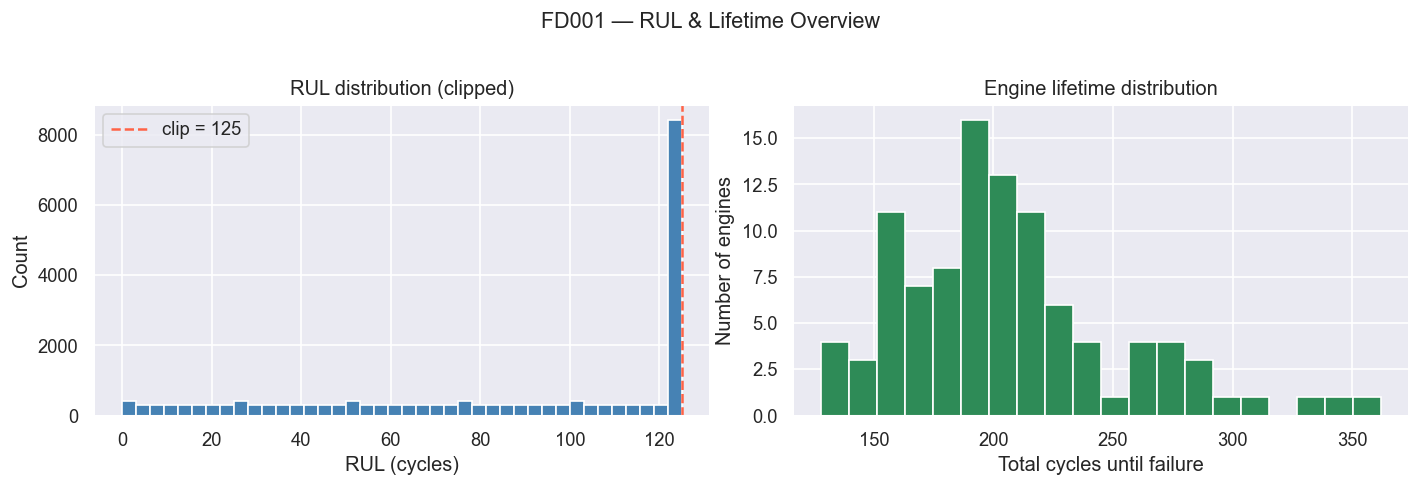

INFO | Median engine lifetime: 199 cycles
INFO | Min / Max lifetime    : 128 / 362 cycles


In [17]:
# Visualise RUL distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(train["rul"], bins=40, edgecolor="white", color="steelblue")
axes[0].axvline(RUL_CLIP, color="tomato", linestyle="--", label=f"clip = {RUL_CLIP}")
axes[0].set_title("RUL distribution (clipped)")
axes[0].set_xlabel("RUL (cycles)")
axes[0].set_ylabel("Count")
axes[0].legend()

# Engine lifetime distribution
lifetimes = train_raw.groupby("unit_id")["cycle"].max()
axes[1].hist(lifetimes, bins=20, edgecolor="white", color="seagreen")
axes[1].set_title("Engine lifetime distribution")
axes[1].set_xlabel("Total cycles until failure")
axes[1].set_ylabel("Number of engines")

plt.suptitle("FD001 — RUL & Lifetime Overview", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

log.info("Median engine lifetime: %.0f cycles", lifetimes.median())
log.info("Min / Max lifetime    : %d / %d cycles", lifetimes.min(), lifetimes.max())

## 3 · Sensor audit — find constant sensors

Several sensors in CMAPSS have near-zero variance across the entire dataset.  
These carry **no degradation signal** and should be dropped before modelling.

In [18]:
SENSOR_COLS = [c for c in train.columns if c.startswith("sensor_")]
STD_THRESHOLD = 0.001

sensor_std = train[SENSOR_COLS].std().sort_values()

constant_sensors = sensor_std[sensor_std < STD_THRESHOLD].index.tolist()
useful_sensors   = sensor_std[sensor_std >= STD_THRESHOLD].index.tolist()

print(f"Total sensors  : {len(SENSOR_COLS)}")
print(f"Constant (drop): {len(constant_sensors)} → {constant_sensors}")
print(f"Useful  (keep) : {len(useful_sensors)}")

Total sensors  : 21
Constant (drop): 6 → ['sensor_01', 'sensor_19', 'sensor_18', 'sensor_10', 'sensor_16', 'sensor_05']
Useful  (keep) : 15


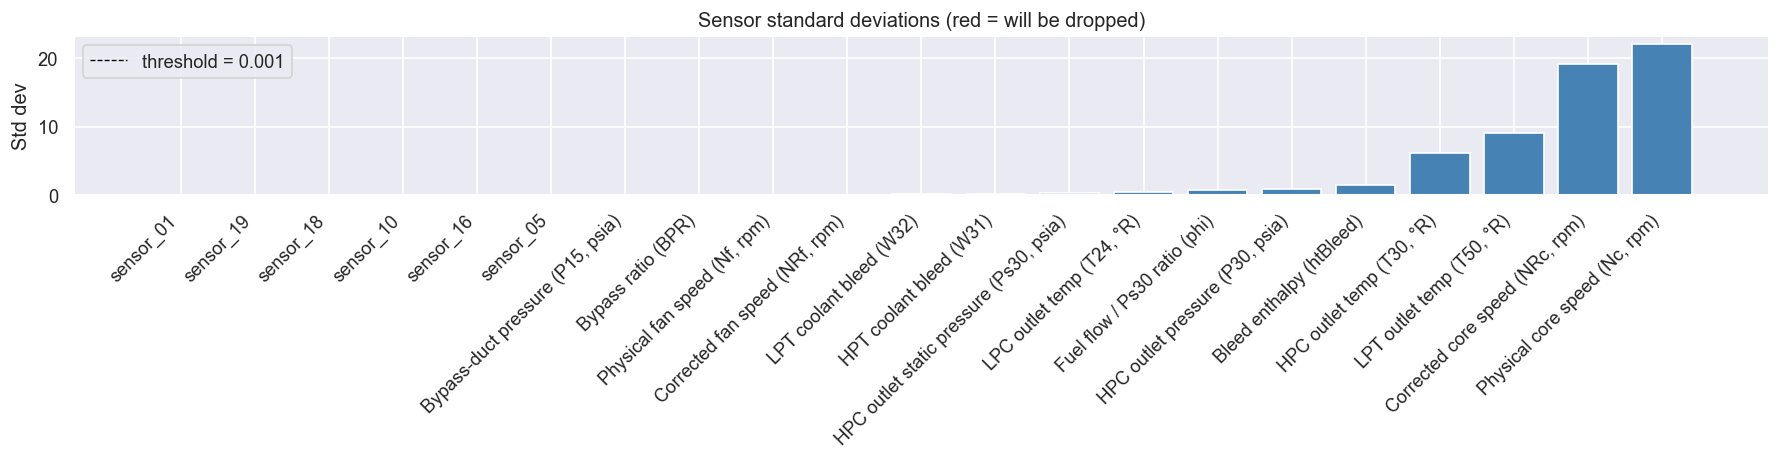

In [19]:
# Bar chart of sensor standard deviations — labelled with physical names
fig, ax = plt.subplots(figsize=(15, 4))
colors = ["tomato" if s < STD_THRESHOLD else "steelblue" for s in sensor_std]
labels = [SENSOR_LABELS.get(s, s) for s in sensor_std.index]
ax.bar(labels, sensor_std.values, color=colors)
ax.axhline(STD_THRESHOLD, color="black", linestyle="--", linewidth=0.8, label=f"threshold = {STD_THRESHOLD}")
ax.set_title("Sensor standard deviations (red = will be dropped)")
ax.set_ylabel("Std dev")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 4 · Correlation with RUL

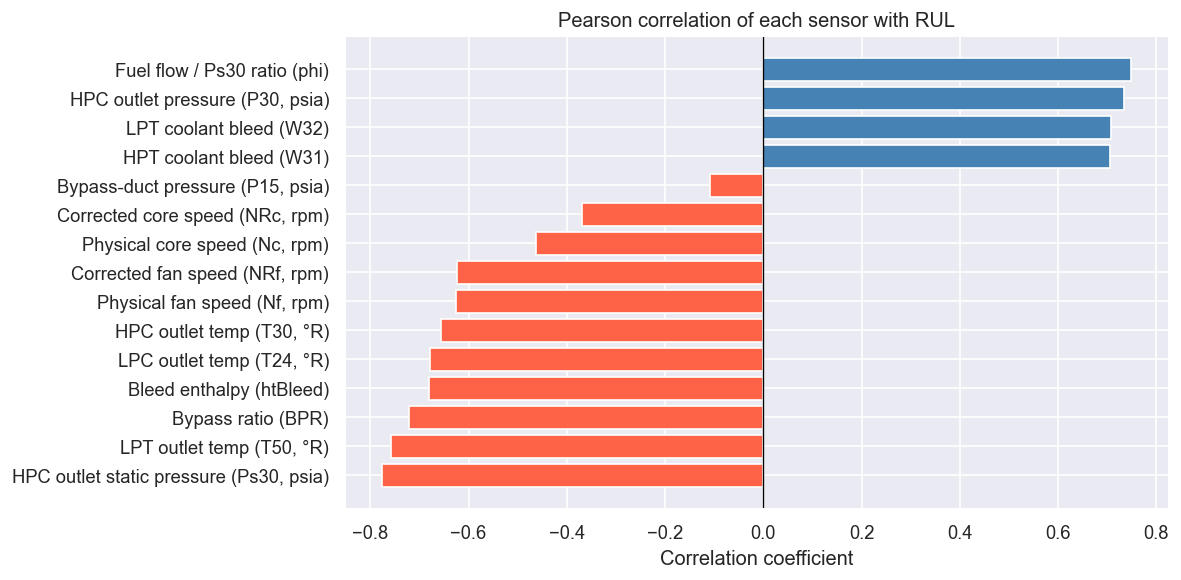


Top 5 positive correlations (sensor INCREASES as engine has more life):
sensor_06   -0.108
sensor_20    0.705
sensor_21    0.707
sensor_07    0.733
sensor_12    0.749
Name: rul, dtype: float64

Top 5 negative correlations (sensor INCREASES as engine DEGRADES):
sensor_11   -0.775
sensor_04   -0.757
sensor_15   -0.721
sensor_17   -0.681
sensor_02   -0.678
Name: rul, dtype: float64


In [20]:
corr_with_rul = (
    train[useful_sensors + ["rul"]]
    .corr()["rul"]
    .drop("rul")
    .sort_values()
)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["tomato" if v < 0 else "steelblue" for v in corr_with_rul]
labels = [SENSOR_LABELS.get(s, s) for s in corr_with_rul.index]
ax.barh(labels, corr_with_rul.values, color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Pearson correlation of each sensor with RUL")
ax.set_xlabel("Correlation coefficient")
plt.tight_layout()
plt.show()

print("\nTop 5 positive correlations (sensor INCREASES as engine has more life):")
print(corr_with_rul.tail(5).round(3))
print("\nTop 5 negative correlations (sensor INCREASES as engine DEGRADES):")
print(corr_with_rul.head(5).round(3))

## 5 · Degradation curves

Plot the **last 100 cycles** of 10 random engines for the top-4 most correlated sensors.  
A good degradation sensor should show a clear trend as the engine approaches failure (cycle 0).

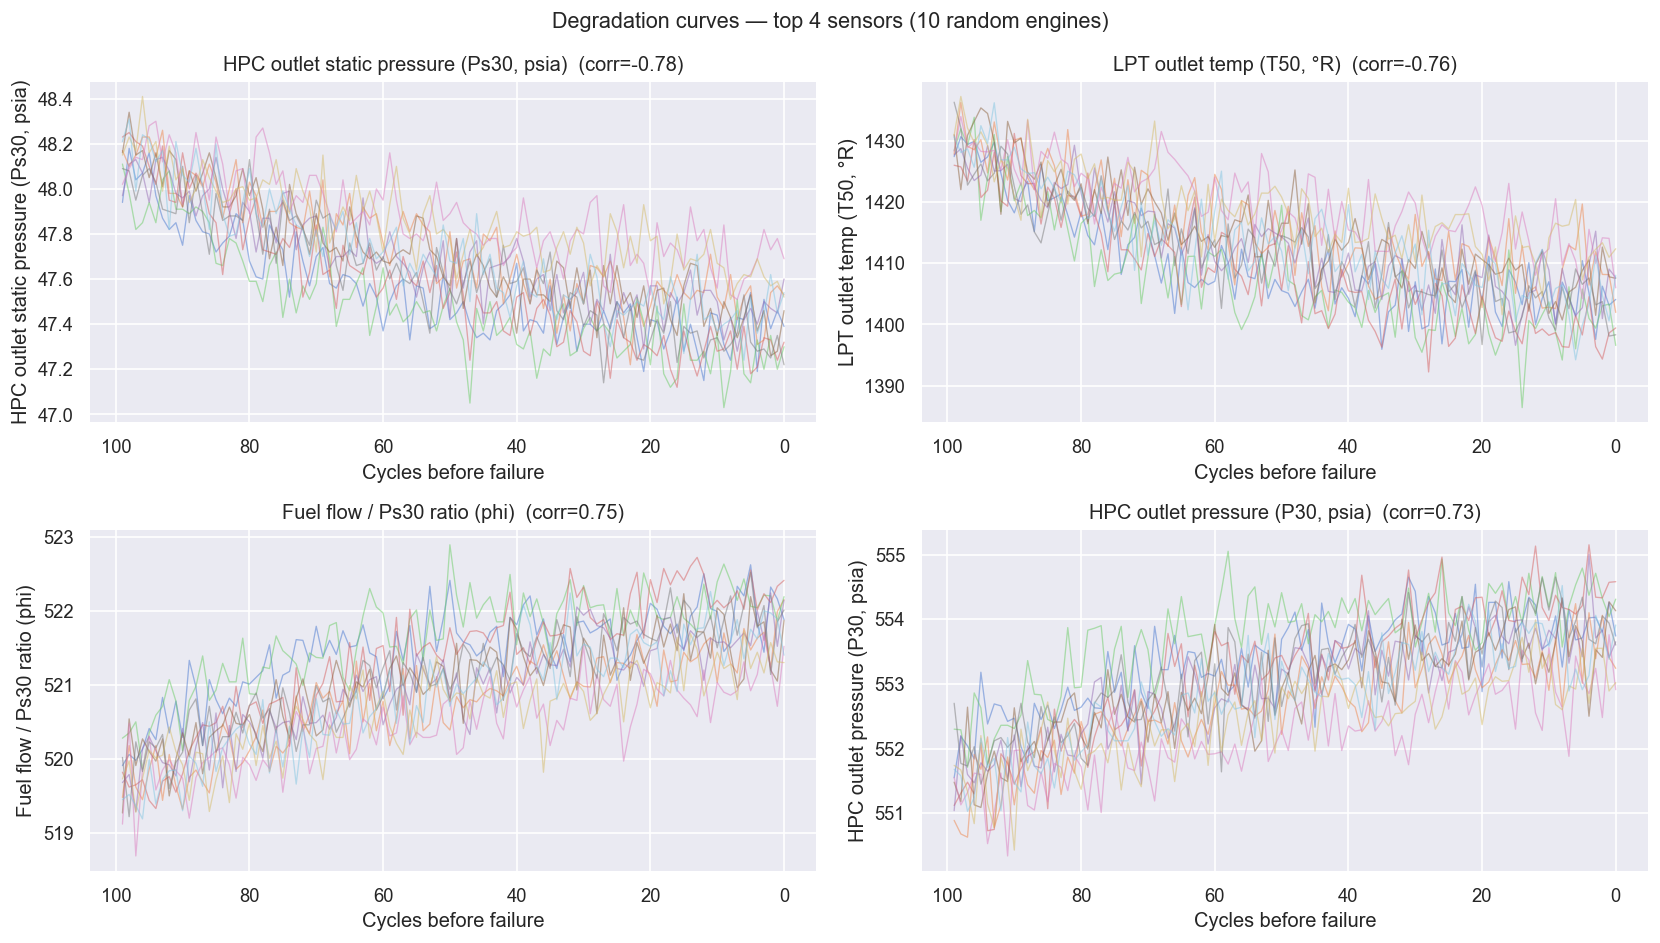

In [21]:
rng = np.random.default_rng(42)
sample_engines = rng.choice(train["unit_id"].unique(), size=10, replace=False)

top_sensors = (
    corr_with_rul.abs().sort_values(ascending=False).head(4).index.tolist()
)

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for ax, sensor in zip(axes, top_sensors):
    label = SENSOR_LABELS.get(sensor, sensor)
    for uid in sample_engines:
        eng = train[train["unit_id"] == uid].tail(100)
        ax.plot(eng["rul"].values[::-1], eng[sensor].values,
                alpha=0.5, linewidth=0.8)
    ax.set_xlabel("Cycles before failure")
    ax.set_ylabel(label)
    ax.set_title(f"{label}  (corr={corr_with_rul[sensor]:.2f})")
    ax.invert_xaxis()  # 0 = failure, left side of plot

plt.suptitle("Degradation curves — top 4 sensors (10 random engines)", fontsize=13)
plt.tight_layout()
plt.show()

## 6 · Save processed data

We save the training DataFrame (with RUL + constant sensors still in, dropping happens in notebook 02) as `.parquet` — faster reads and smaller files than CSV.

In [22]:
out_path = DATA_PROC / "train_FD001_with_rul.parquet"
train.to_parquet(out_path, index=False)
log.info("Saved → %s  (%s rows)", out_path.name, len(train))

# Also persist the list of useful sensors for notebook 02
import json

meta = {
    "useful_sensors": useful_sensors,
    "constant_sensors": constant_sensors,
    "rul_clip": RUL_CLIP,
}
(DATA_PROC / "eda_meta.json").write_text(json.dumps(meta, indent=2))
log.info("Saved EDA metadata → eda_meta.json")

print("\nAll done. Files in data/:")
for f in sorted(DATA_PROC.iterdir()):
    print(" ", f.name)

INFO | Saved → train_FD001_with_rul.parquet  (20631 rows)
INFO | Saved EDA metadata → eda_meta.json



All done. Files in data/:
  eda_meta.json
  feature_meta.json
  train_FD001_with_rul.parquet
  train_features.parquet
  val_features.parquet


---
### EDA Summary

| Item | Finding |
|------|---------|
| Dataset | 100 engines, 1 operating condition, 1 fault mode |
| Total training rows | ~20,631 |
| Missing values | None |
| Constant sensors (dropped in 02) | sensors 01, 05, 10, 16, 18, 19 |
| Useful sensors | 15 |
| RUL clip | 125 cycles |
| Strongest degradation signals | sensors 11, 04, 12, 07 |

**Next notebook → `02_feature_engineering.ipynb`**